**This notebook tackles the final problem of the project, where we compare five different model architectures on the Fashion-MNIST dataset. We will address each sub-module in a separate section.**

***Imports and Global setup***

In [1]:
# Standard Libraries
import numpy as np
import matplotlib.pyplot as plt
import os
import time
from collections import OrderedDict

# We will use outr own Custom Library where ever it is needed. 

# random seed for reproducibility
np.random.seed(42)

**5.1 Data Loading and Preprocessing**


In [2]:
# importing from our own library.
from my_ml_lib.datasets import load_fashion_mnist
from my_ml_lib.model_selection import train_test_split
import os


# loading the data
print("Loading Fashion-MNIST data using my_ml_lib.datasets.load_fashion_mnist...")
DATA_PATH = "data"
X_train_full, y_train_full = load_fashion_mnist(data_folder=DATA_PATH, kind='train')
X_test, y_test = load_fashion_mnist(data_folder=DATA_PATH, kind='test')
print("Data loaded and normalized successfully.")

# Split the Training Data into Training and Validation Sets
# We will use our own train_test_split function to create the validation set 
# for hyperparameter tuning. The X_test, y_test set remains untouched for final evaluation.
print("Splitting full training data into training and validation sets...")
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42
)

# printing Shapes to Verify
print("\n--- Data Shapes ---")
print(f"Training set:   X_train.shape = {X_train.shape}, y_train.shape = {y_train.shape}")
print(f"Validation set: X_val.shape   = {X_val.shape}, y_val.shape   = {y_val.shape}")
print(f"Test set:       X_test.shape  = {X_test.shape}, y_test.shape  = {y_test.shape}")

Loading Fashion-MNIST data using my_ml_lib.datasets.load_fashion_mnist...
Data loaded and normalized successfully.
Splitting full training data into training and validation sets...

--- Data Shapes ---
Training set:   X_train.shape = (48000, 784), y_train.shape = (48000,)
Validation set: X_val.shape   = (12000, 784), y_val.shape   = (12000,)
Test set:       X_test.shape  = (10000, 784), y_test.shape  = (10000,)


**5.3 The Model Types**

we will now investigate the performance of the following five distinct model architectures on the Fashion-MNIST dataset. We will train and tune each model to find its best performing configuration before comparing them.

*   **1. OvR Logistic Regression**: Using our binary `LogisticRegression` model in a One-vs-Rest (OvR) scheme.
*   **2. Softmax Regression (Raw)**: Using our autograd engine directly on the raw pixel data.
*   **3. Softmax + Polynomial Features**: Applying our `PolynomialFeatures` transformer before the Softmax model.
*   **4. Softmax + Gaussian Basis Features**: Applying our `GaussianBasisFeatures` transformer before the Softmax model.
*   **5. MLP**: A Multi-Layer Perceptron built with our autograd engine's `Linear` and `ReLU` layers.


**5.3.1 Model 1: OvR Logistic Regression**

For our first model, we will use the `LogisticRegression` classifier in a One-vs-Rest (OvR) scheme. The process is as follows:

1.  **Training**: We will train 10 separate binary `LogisticRegression` classifiers. Each classifier `i` (for `i` in 0 to 9) is trained to distinguish class `i` (as the positive class) from all other classes (as the negative class).
2.  **Prediction**: To make a prediction for a new sample, we feed it to all 10 classifiers. Each classifier outputs a probability that the sample belongs to its positive class. The final predicted class is the one corresponding to the classifier that output the highest probability.
3.  **Tuning**: The main hyperparameter for this model is the L2 regularization strength, `alpha`. We will experiment with a range of `alpha` values (e.g., `[0.001, 0.01, 0.1, 1.0]`). For each `alpha`, we will train a full set of 10 classifiers and evaluate their combined accuracy on the **validation set**.
4.  **Selection**: The `alpha` value that yields the highest accuracy on the validation set will be chosen as the optimal hyperparameter. The set of 10 models trained with this best `alpha` will be our final OvR model.
5.  **Final Evaluation**: Finally, we will take this best OvR model and evaluate its performance once on the unseen **test set** to get our final reported accuracy.


In [3]:
# Import necessary libraries
from my_ml_lib.linear_models.classification import LogisticRegression
from tqdm.notebook import tqdm
import time
import itertools
import numpy as np
import pickle # For saving the final classical models

# Main Dictionary to Store All Results
# We will add results from all 5 models to this dictionary
final_results = {}

# 1. Define Hyperparameter Grid for OvR Logistic Regression 
print("--- Starting Full Workflow for Model 1: OvR Logistic Regression (SGD) ---")

param_grid_ovr = {
    'alpha': [0.0001, 0.001],
    'lr': [0.1, 0.05],
    'epochs': [40,80] 
}
# Note: A smaller grid is used here to keep the process fast

all_params_ovr = [dict(zip(param_grid_ovr.keys(), v)) for v in itertools.product(*param_grid_ovr.values())]

best_ovr_params = None
best_ovr_val_acc = 0.0

# 2. Grid Search to Find Best Hyperparameters 
for params in tqdm(all_params_ovr, desc="OvR Grid Search"):
    alpha, lr, epochs = params['alpha'], params['lr'], params['epochs']
    
    current_models = []
    # Train 10 classifiers for the current hyperparameter set
    for i in range(10):
        y_train_binary = (y_train == i).astype(int)
        log_reg = LogisticRegression(alpha=alpha, epochs=epochs, lr=lr, random_state=42)
        log_reg.fit(X_train, y_train_binary)
        current_models.append(log_reg)
    
    # Validate the current set of models
    val_probas = np.zeros((X_val.shape[0], 10))
    for i, model in enumerate(current_models):
        val_probas[:, i] = model.predict_proba(X_val)[:, 1]
    
    y_val_pred = np.argmax(val_probas, axis=1)
    val_accuracy = np.mean(y_val_pred == y_val)
    print(f"Params: {params} -> Val Accuracy: {val_accuracy:.4f}")
    
    # Update best parameters if current model is better
    if val_accuracy > best_ovr_val_acc:
        best_ovr_val_acc = val_accuracy
        best_ovr_params = params
        print(f"*** New best params found: {best_ovr_params} ***")

print(f"\nBest Hyperparameters found for OvR: {best_ovr_params} with Validation Accuracy: {best_ovr_val_acc:.4f}")


# 3. Retrain the Best Model and Store Results ---
print("\n Retraining best OvR model on full training data and evaluating ---")

# This dictionary will store all results for this specific model
ovr_run_results = {
    'best_params': best_ovr_params,
    'val_accuracy': best_ovr_val_acc,
    'train_accuracy': 0, # Will calculate this now
    'test_accuracy': 0, # Will calculate this now
    'model_objects': [] # Will store the 10 trained classifiers
}

# Retrain the 10 classifiers with the best hyperparameters
final_ovr_models = []
for i in tqdm(range(10), desc="Retraining Best OvR Model"):
    y_train_binary = (y_train == i).astype(int)
    final_log_reg = LogisticRegression(**best_ovr_params, random_state=42)
    final_log_reg.fit(X_train, y_train_binary)
    final_ovr_models.append(final_log_reg)

ovr_run_results['model_objects'] = final_ovr_models

# 4. Final Evaluation on Train and Test Sets ---
# Evaluate on the Training Set
train_probas = np.zeros((X_train.shape[0], 10))
for i, model in enumerate(final_ovr_models):
    train_probas[:, i] = model.predict_proba(X_train)[:, 1]
y_train_pred = np.argmax(train_probas, axis=1)
ovr_run_results['train_accuracy'] = np.mean(y_train_pred == y_train)

# Evaluate on the Test Set
test_probas = np.zeros((X_test.shape[0], 10))
for i, model in enumerate(final_ovr_models):
    test_probas[:, i] = model.predict_proba(X_test)[:, 1]
y_test_pred = np.argmax(test_probas, axis=1)
ovr_run_results['test_accuracy'] = np.mean(y_test_pred == y_test)

# 5. Save Model and Add to Master Results ---
# Save the list of 10 classifiers using pickle
with open("saved_models/ovr_logistic_model.pkl", "wb") as f:
    pickle.dump(final_ovr_models, f)

# Add this model's results to the master dictionary
final_results['ovr_logistic'] = ovr_run_results

print("\n--- Model 1 (OvR Logistic) Workflow Complete ---")
print(f"Final Train Accuracy: {ovr_run_results['train_accuracy']:.4f}")
print(f"Final Test Accuracy: {ovr_run_results['test_accuracy']:.4f}")
print("Results stored in `final_results['ovr_logistic']`.")
print("Model saved to `saved_models/ovr_logistic_model.pkl`.")

# Display the final results dictionary for this model
final_results['ovr_logistic']


--- Starting Full Workflow for Model 1: OvR Logistic Regression (SGD) ---


OvR Grid Search:   0%|          | 0/8 [00:00<?, ?it/s]

Params: {'alpha': 0.0001, 'lr': 0.1, 'epochs': 40} -> Val Accuracy: 0.9111
*** New best params found: {'alpha': 0.0001, 'lr': 0.1, 'epochs': 40} ***
Params: {'alpha': 0.0001, 'lr': 0.1, 'epochs': 80} -> Val Accuracy: 0.9120
*** New best params found: {'alpha': 0.0001, 'lr': 0.1, 'epochs': 80} ***
Params: {'alpha': 0.0001, 'lr': 0.05, 'epochs': 40} -> Val Accuracy: 0.9103
Params: {'alpha': 0.0001, 'lr': 0.05, 'epochs': 80} -> Val Accuracy: 0.9113
Params: {'alpha': 0.001, 'lr': 0.1, 'epochs': 40} -> Val Accuracy: 0.9053
Params: {'alpha': 0.001, 'lr': 0.1, 'epochs': 80} -> Val Accuracy: 0.9064
Params: {'alpha': 0.001, 'lr': 0.05, 'epochs': 40} -> Val Accuracy: 0.9064
Params: {'alpha': 0.001, 'lr': 0.05, 'epochs': 80} -> Val Accuracy: 0.9068

Best Hyperparameters found for OvR: {'alpha': 0.0001, 'lr': 0.1, 'epochs': 80} with Validation Accuracy: 0.9120

 Retraining best OvR model on full training data and evaluating ---


Retraining Best OvR Model:   0%|          | 0/10 [00:00<?, ?it/s]


--- Model 1 (OvR Logistic) Workflow Complete ---
Final Train Accuracy: 0.9224
Final Test Accuracy: 0.9169
Results stored in `final_results['ovr_logistic']`.
Model saved to `saved_models/ovr_logistic_model.pkl`.


{'best_params': {'alpha': 0.0001, 'lr': 0.1, 'epochs': 80},
 'val_accuracy': np.float64(0.912),
 'train_accuracy': np.float64(0.9224375),
 'test_accuracy': np.float64(0.9169),
 'model_objects': [<my_ml_lib.linear_models.classification._logistic.LogisticRegression at 0x23f5b817e50>,
  <my_ml_lib.linear_models.classification._logistic.LogisticRegression at 0x23f5b8174d0>]}

**5.3.2 Model 2: Softmax Regression (Raw Pixels)**

We now implement our first model using the custom autograd engine. Softmax Regression can be thought of as a simple neural network with no hidden layers. It consists of a single `Linear` layer that maps the input features (784 raw pixels) directly to the output logits for the 10 classes.

**Process:**

1.  **Model Definition**: We will use our `Sequential` container to define the model, which will contain a single `Linear(in_features=784, out_features=10)` layer.
2.  **Training**: The model will be trained using our custom `SGD` optimizer and `CrossEntropyLoss` function. To make the code reusable for subsequent models, we will create a generic `train_autograd_model` function that encapsulates the mini-batch training loop.
3.  **Tuning**: We will perform a grid search to find the best-performing hyperparameters, specifically the **learning rate (`lr`)**, the number of **`epochs`**, and the **`batch_size`**, by evaluating the accuracy on the validation set.
4.  **Evaluation**: The best model configuration found during tuning will be evaluated once on the unseen test set to report its final performance.


In [4]:
# Importing necessary libraries
from my_ml_lib.nn.autograd import Value
from my_ml_lib.nn.modules.base import Module
from my_ml_lib.nn.modules.linear import Linear
from my_ml_lib.nn.modules.containers import Sequential
from my_ml_lib.nn.losses import CrossEntropyLoss
from my_ml_lib.nn.optim import SGD
from tqdm.notebook import tqdm
import time
import itertools
import numpy as np

# 1. Generic Training Function for Autograd Models ---
# We will reuse this function for Models 2, 3, 4, and 5
def train_autograd_model(model, optimizer, criterion, 
                         X_train, y_train, X_val, y_val, 
                         epochs, batch_size, print_every=10):
    """
    A generic function to train a model built with our autograd engine.
    Returns the history of training losses and validation accuracies.
    """
    train_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        # Mini-batch training
        batch_losses = []
        # Shuffle data for each epoch
        shuffled_indices = np.random.permutation(len(X_train))
        
        for i in tqdm(range(0, len(X_train), batch_size), desc=f"Epoch {epoch+1}/{epochs}", leave=False):
            batch_indices = shuffled_indices[i:i + batch_size]
            X_batch = X_train[batch_indices]
            y_batch = y_train[batch_indices]
            
            # 1. Zero gradients
            model.zero_grad()
            
            # 2. Forward pass
            logits = model(Value(X_batch))
            
            # 3. Calculate loss
            loss = criterion(logits, y_batch)
            batch_losses.append(loss.data.item())
            
            # 4. Backward pass
            loss.backward()
            
            # 5. Update weights
            optimizer.step()
        
        train_loss = np.mean(batch_losses)
        train_losses.append(train_loss)

        # Validation at the end of the epoch
        val_logits = model(Value(X_val))
        y_val_pred = np.argmax(val_logits.data, axis=1)
        val_accuracy = np.mean(y_val_pred == y_val)
        val_accuracies.append(val_accuracy)
        
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")
            
    return train_losses, val_accuracies

# 2. Hyperparameter Tuning for Softmax Regression ---
print("--- Starting Full Workflow for Model 2: Softmax Regression ---")

param_grid_softmax = {
    'lr': [0.1, 0.05],
    'epochs': [20, 40],
    'batch_size': [128, 256]
}

all_params_softmax = [dict(zip(param_grid_softmax.keys(), v)) for v in itertools.product(*param_grid_softmax.values())]

best_softmax_params = None
best_softmax_val_acc = 0.0

# Grid Search ---
for params in tqdm(all_params_softmax, desc="Softmax Grid Search"):
    lr, epochs, batch_size = params['lr'], params['epochs'], params['batch_size']
    print(f"\nTraining Softmax with lr={lr}, epochs={epochs}, batch_size={batch_size}...")

    softmax_model = Sequential(Linear(in_features=784, out_features=10))
    optimizer = SGD(softmax_model.parameters(), lr=lr)
    criterion = CrossEntropyLoss()

    _, val_accuracies = train_autograd_model(
        softmax_model, optimizer, criterion, X_train, y_train, X_val, y_val, 
        epochs=epochs, batch_size=batch_size, print_every=10
    )
    
    final_val_acc = val_accuracies[-1]
    if final_val_acc > best_softmax_val_acc:
        best_softmax_val_acc = final_val_acc
        best_softmax_params = params
        print(f"*** New best params found: {params} with accuracy {final_val_acc:.4f} ***")

print(f"\nBest Hyperparameters for Softmax: {best_softmax_params} with Validation Accuracy: {best_softmax_val_acc:.4f}")

# 3. Retrain Best Model and Store Results ---
print("\n--- Retraining best Softmax model on full training data and evaluating ---")

final_softmax_model = Sequential(Linear(in_features=784, out_features=10))
optimizer = SGD(final_softmax_model.parameters(), lr=best_softmax_params['lr'])
criterion = CrossEntropyLoss()

train_losses_softmax, _ = train_autograd_model(
    final_softmax_model, optimizer, criterion, X_train, y_train, X_val, y_val, 
    epochs=best_softmax_params['epochs'], batch_size=best_softmax_params['batch_size'], print_every=5
)

# 4. Final Evaluation ---
train_logits = final_softmax_model(Value(X_train))
y_train_pred = np.argmax(train_logits.data, axis=1)
train_accuracy_softmax = np.mean(y_train_pred == y_train)

test_logits = final_softmax_model(Value(X_test))
y_test_pred = np.argmax(test_logits.data, axis=1)
test_accuracy_softmax = np.mean(y_test_pred == y_test)

# 5. Save Model and Add to Master Results ---
final_softmax_model.save_state_dict("saved_models/softmax_model.npz")

final_results['softmax_raw'] = {
    'best_params': best_softmax_params,
    'val_accuracy': best_softmax_val_acc,
    'train_accuracy': train_accuracy_softmax,
    'test_accuracy': test_accuracy_softmax,
    'train_losses': train_losses_softmax,
    'model_object': final_softmax_model
}

print("\n--- Model 2 (Softmax Regression) Workflow Complete ---")
print(f"Final Train Accuracy: {train_accuracy_softmax:.4f}")
print(f"Final Test Accuracy: {test_accuracy_softmax:.4f}")
print("Results stored in `final_results['softmax_raw']`.")
print("Model saved to `saved_models/softmax_model.npz`.")

# Display the final results dictionary for this model
final_results['softmax_raw']


--- Starting Full Workflow for Model 2: Softmax Regression ---


Softmax Grid Search:   0%|          | 0/8 [00:00<?, ?it/s]


Training Softmax with lr=0.1, epochs=20, batch_size=128...


Epoch 1/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 2/20:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 3/20:   0%|          | 0/375 [00:00<?, ?it/s]

... (306 outputs left out)

Epoch 39/40:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 40/40:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 40/40 | Train Loss: 0.2599 | Val Accuracy: 0.9207
State dictionary saved to saved_models/softmax_model.npz

--- Model 2 (Softmax Regression) Workflow Complete ---
Final Train Accuracy: 0.9289
Final Test Accuracy: 0.9236
Results stored in `final_results['softmax_raw']`.
Model saved to `saved_models/softmax_model.npz`.


{'best_params': {'lr': 0.1, 'epochs': 40, 'batch_size': 128},
 'val_accuracy': np.float64(0.921),
 'train_accuracy': np.float64(0.9288541666666666),
 'test_accuracy': np.float64(0.9236),
 'train_losses': [np.float64(0.6182517264177292),
  np.float64(0.39027916896507314),
  np.float64(0.3541619642798891),
  np.float64(0.3355587035815593),
  np.float64(0.32399801495882363),
  np.float64(0.3151197798001638),
  np.float64(0.3087417489517552),
  np.float64(0.30350463569191455),
  np.float64(0.299127596768532),
  np.float64(0.29559370857693934),
  np.float64(0.292355581657405),
  np.float64(0.2896554259077783),
  np.float64(0.287073622549875),
  np.float64(0.2850135716562771),
  np.float64(0.28307103726078797),
  np.float64(0.28128118294663124),
  np.float64(0.27985960912505575),
  np.float64(0.2780954637636371),
  np.float64(0.27667891730734195),
  np.float64(0.275261033911012),
  np.float64(0.2743205625302172),
  np.float64(0.27308717327509546),
  np.float64(0.2720084631247032),
  np.float

**5.3.3 Model 3: Softmax + Polynomial Features**

This model investigates whether creating explicit non-linear features can improve the performance of our Softmax Regression classifier.

**Approach**:
1.  **Downsampling**: To manage the computational cost of polynomial feature generation, we first downsample the 28x28 images to a more manageable 8x8 size (64 features). This is a necessary step to prevent memory errors and extremely long training times.
2.  **Feature Transformation**: We then apply our `PolynomialFeatures` transformer to this smaller 64-feature dataset to create interaction terms.
3.  **Tuning**: A grid search is performed to find the best hyperparameters, including the polynomial **`degree`**, as well as the optimizer's **`lr`**, **`epochs`**, and **`batch_size`**.
4.  **Training & Evaluation**: The transformed data is used to train a `Sequential` model with a single `Linear` layer. The best configuration is found using the validation set and then evaluated on the transformed test set.


In [5]:
# Importing the  necessary libraries
from my_ml_lib.preprocessing import PolynomialFeatures
from skimage.transform import resize # this i am using for image downsampling
import numpy as np
from tqdm.notebook import tqdm
import itertools
import time

# 1. Downsample Image Data(else we need to suffer with the memory error) 
print("Preparing Data for Model 3: Softmax + Polynomial Features ---")
print("Downsampling images to 8x8 to make PolynomialFeatures feasible...")

IMG_SIZE = 8
X_train_downsampled = np.array([resize(img.reshape(28, 28), (IMG_SIZE, IMG_SIZE)) for img in X_train]).reshape(-1, IMG_SIZE * IMG_SIZE)
X_val_downsampled = np.array([resize(img.reshape(28, 28), (IMG_SIZE, IMG_SIZE)) for img in X_val]).reshape(-1, IMG_SIZE * IMG_SIZE)
X_test_downsampled = np.array([resize(img.reshape(28, 28), (IMG_SIZE, IMG_SIZE)) for img in X_test]).reshape(-1, IMG_SIZE * IMG_SIZE)

print(f"Downsampled training data shape: {X_train_downsampled.shape}")

# 2. Hyperparameter Tuning 
param_grid_poly = {
    'degree': [2], # For me degree 3 causes a MemoryError. So i am sticking to 2.
    'lr': [0.05, 0.01],
    'epochs': [40],
    'batch_size': [256]
}

all_params_poly = [dict(zip(param_grid_poly.keys(), v)) for v in itertools.product(*param_grid_poly.values())]

best_poly_params = None
best_poly_val_acc = 0.0

for params in tqdm(all_params_poly, desc="Polynomial Grid Search"):
    degree, lr, epochs, batch_size = params['degree'], params['lr'], params['epochs'], params['batch_size']
    print(f"\nTraining with degree={degree}, lr={lr}, epochs={epochs}, batch_size={batch_size}...")

    # Apply Polynomial Feature Transformation
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_downsampled)
    X_val_poly = poly.transform(X_val_downsampled)
    print(f"Polynomial transform created {X_train_poly.shape[1]} features.")

    # Define the model architecture based on the new number of features
    poly_model = Sequential(Linear(in_features=X_train_poly.shape[1], out_features=10))
    optimizer = SGD(poly_model.parameters(), lr=lr)
    criterion = CrossEntropyLoss()

    # Train the model using our generic function
    _, val_accuracies = train_autograd_model(
        poly_model, optimizer, criterion, X_train_poly, y_train, X_val_poly, y_val, 
        epochs=epochs, batch_size=batch_size, print_every=10
    )
    
    final_val_acc = val_accuracies[-1]
    if final_val_acc > best_poly_val_acc:
        best_poly_val_acc = final_val_acc
        best_poly_params = params
        print(f"*** New best params found: {params} with accuracy {final_val_acc:.4f} ***")

print(f"\nBest Hyperparameters for Softmax + Poly: {best_poly_params} with Validation Accuracy: {best_poly_val_acc:.4f}")

# 3. Retrain Best Model and Store Results ---
print("\n--- Retraining best Softmax + Poly model and evaluating ---")

# Apply the best polynomial transformation
final_poly_transformer = PolynomialFeatures(degree=best_poly_params['degree'])
X_train_final_poly = final_poly_transformer.fit_transform(X_train_downsampled)
X_val_final_poly = final_poly_transformer.transform(X_val_downsampled)
X_test_final_poly = final_poly_transformer.transform(X_test_downsampled)

# Retrain the model on the transformed data
final_poly_model = Sequential(Linear(in_features=X_train_final_poly.shape[1], out_features=10))
optimizer = SGD(final_poly_model.parameters(), lr=best_poly_params['lr'])
criterion = CrossEntropyLoss()

train_losses_poly, _ = train_autograd_model(
    final_poly_model, optimizer, criterion, X_train_final_poly, y_train, X_val_final_poly, y_val,
    epochs=best_poly_params['epochs'], batch_size=best_poly_params['batch_size'], print_every=5
)

# 4. Final Evaluation 
train_logits = final_poly_model(Value(X_train_final_poly))
y_train_pred = np.argmax(train_logits.data, axis=1)
train_accuracy_poly = np.mean(y_train_pred == y_train)

test_logits = final_poly_model(Value(X_test_final_poly))
y_test_pred = np.argmax(test_logits.data, axis=1)
test_accuracy_poly = np.mean(y_test_pred == y_test)

# 5. Save Model and Add to Master Results 
final_poly_model.save_state_dict("saved_models/softmax_poly_model.npz")

final_results['softmax_poly'] = {
    'best_params': best_poly_params,
    'val_accuracy': best_poly_val_acc,
    'train_accuracy': train_accuracy_poly,
    'test_accuracy': test_accuracy_poly,
    'train_losses': train_losses_poly,
    'model_object': final_poly_model
}

print("\n--- Model 3 (Softmax + Poly) Workflow Complete ---")
print(f"Final Train Accuracy: {train_accuracy_poly:.4f}")
print(f"Final Test Accuracy: {test_accuracy_poly:.4f}")
print("Results stored in `final_results['softmax_poly']`.")
print("Model saved to `saved_models/softmax_poly_model.npz`.")

# Display the final results dictionary for this model
final_results['softmax_poly']


Preparing Data for Model 3: Softmax + Polynomial Features ---
Downsampling images to 8x8 to make PolynomialFeatures feasible...
Downsampled training data shape: (48000, 64)


Polynomial Grid Search:   0%|          | 0/2 [00:00<?, ?it/s]


Training with degree=2, lr=0.05, epochs=40, batch_size=256...
Polynomial transform created 2145 features.


Epoch 1/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 3/40:   0%|          | 0/188 [00:00<?, ?it/s]

... (130 outputs left out)

Epoch 39/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40 | Train Loss: 0.3837 | Val Accuracy: 0.8935
State dictionary saved to saved_models/softmax_poly_model.npz

--- Model 3 (Softmax + Poly) Workflow Complete ---
Final Train Accuracy: 0.8978
Final Test Accuracy: 0.9043
Results stored in `final_results['softmax_poly']`.
Model saved to `saved_models/softmax_poly_model.npz`.


{'best_params': {'degree': 2, 'lr': 0.05, 'epochs': 40, 'batch_size': 256},
 'val_accuracy': np.float64(0.89425),
 'train_accuracy': np.float64(0.8977916666666667),
 'test_accuracy': np.float64(0.9043),
 'train_losses': [np.float64(1.6933479218585201),
  np.float64(1.1327156696284446),
  np.float64(0.9191358303564117),
  np.float64(0.804622813949826),
  np.float64(0.7317104976804015),
  np.float64(0.6806919972003601),
  np.float64(0.6420462672474316),
  np.float64(0.6119357587451708),
  np.float64(0.5873669593551061),
  np.float64(0.5669672437935755),
  np.float64(0.5498322674608611),
  np.float64(0.5347186019973978),
  np.float64(0.52124168297621),
  np.float64(0.5096635302803647),
  np.float64(0.4992892385807956),
  np.float64(0.4901644190834385),
  np.float64(0.4817345324456463),
  np.float64(0.4736288078897869),
  np.float64(0.4666697523412796),
  np.float64(0.45996293048435843),
  np.float64(0.45371870921981505),
  np.float64(0.44818326550922677),
  np.float64(0.44290558939922475)

**5.3.4 Model 4: Softmax + Gaussian Basis Features**

This model explores another feature engineering technique: Gaussian Radial Basis Function (RBF) features. This method transforms the data based on its similarity to a set of prototype "centers."

**Approach**:
1.  **Feature Transformation**: We will use our `GaussianBasisFeatures` transformer on the raw, 784-pixel training data. The transformer will first find a set of `n_centers` by randomly sampling points from the training data. Then, it will transform each image into a new vector of size `n_centers`, where each new feature represents the Gaussian-kernel-transformed distance to one of the centers.
2.  **Tuning**: We will perform a grid search to find the optimal hyperparameters. This is a more complex tuning task as it involves both the pre-processing step and the optimizer. We will tune:
    *   `n_centers`: The number of Gaussian centers (i.e., the dimensionality of our new feature space).
    *   `sigma`: The width of the Gaussian kernels.
    *   `lr`, `epochs`, and `batch_size`: The standard optimizer parameters.
3.  **Training & Evaluation**: The transformed data will be used to train a `Sequential` model with a single `Linear` layer. The best configuration will be identified using the validation set, retrained, and finally evaluated on the transformed test set.


In [6]:
# Importing all necessary libraries
from my_ml_lib.nn.autograd import Value
from my_ml_lib.nn.modules.base import Module
from my_ml_lib.nn.modules.linear import Linear
from my_ml_lib.nn.modules.containers import Sequential
from my_ml_lib.nn.losses import CrossEntropyLoss
from my_ml_lib.nn.optim import SGD
from my_ml_lib.preprocessing import GaussianBasisFeatures
import numpy as np
from tqdm.notebook import tqdm
import itertools
import time

# 1. Hyperparameter Tuning for Softmax + Gaussian Features 
print("--- Starting Full Workflow for Model 4: Softmax + Gaussian Basis Features ---")

param_grid_rbf = {
    'n_centers': [100, 200],
    'sigma': [5.0, 10.0],
    'lr': [0.1, 0.05],
    'epochs': [40],
    'batch_size': [256]
}

all_params_rbf = [dict(zip(param_grid_rbf.keys(), v)) for v in itertools.product(*param_grid_rbf.values())]

best_rbf_params = None
best_rbf_val_acc = 0.0

for params in tqdm(all_params_rbf, desc="RBF Grid Search"):
    n_centers, sigma, lr, epochs, batch_size = params['n_centers'], params['sigma'], params['lr'], params['epochs'], params['batch_size']
    print(f"\nTraining with n_centers={n_centers}, sigma={sigma}, lr={lr}, epochs={epochs}, batch_size={batch_size}...")

    # 1a. Apply Gaussian Feature Transformation 
    rbf = GaussianBasisFeatures(n_centers=n_centers, sigma=sigma, random_state=42)
    # Fit on the training data and transform all datasets
    X_train_rbf = rbf.fit_transform(X_train)
    X_val_rbf = rbf.transform(X_val)
    
    print(f"RBF transform created {X_train_rbf.shape[1]} features.")

    # 1b. Define and Train the Model 
    rbf_model = Sequential(Linear(in_features=n_centers, out_features=10))
    optimizer = SGD(rbf_model.parameters(), lr=lr)
    criterion = CrossEntropyLoss()

    _, val_accuracies = train_autograd_model(
        rbf_model, optimizer, criterion, X_train_rbf, y_train, X_val_rbf, y_val, 
        epochs=epochs, batch_size=batch_size, print_every=10
    )
    
    final_val_acc = val_accuracies[-1]
    if final_val_acc > best_rbf_val_acc:
        best_rbf_val_acc = final_val_acc
        best_rbf_params = params
        print(f"*** New best params found: {params} with accuracy {final_val_acc:.4f} ***")

print(f"\nBest Hyperparameters for Softmax + RBF: {best_rbf_params} with Validation Accuracy: {best_rbf_val_acc:.4f}")


# 2. Retrain Best Model and Store Results 
print("\n--- Retraining best Softmax + RBF model and evaluating ---")

# Apply the best RBF transformation
final_rbf_transformer = GaussianBasisFeatures(
    n_centers=best_rbf_params['n_centers'], 
    sigma=best_rbf_params['sigma'], 
    random_state=42
)
X_train_final_rbf = final_rbf_transformer.fit_transform(X_train)
X_val_final_rbf = final_rbf_transformer.transform(X_val)
X_test_final_rbf = final_rbf_transformer.transform(X_test)

# Retrain the model on the transformed data
final_rbf_model = Sequential(Linear(in_features=best_rbf_params['n_centers'], out_features=10))
optimizer = SGD(final_rbf_model.parameters(), lr=best_rbf_params['lr'])
criterion = CrossEntropyLoss()

train_losses_rbf, _ = train_autograd_model(
    final_rbf_model, optimizer, criterion, X_train_final_rbf, y_train, X_val_final_rbf, y_val,
    epochs=best_rbf_params['epochs'], batch_size=best_rbf_params['batch_size'], print_every=5
)

# 3. Final Evaluation 
train_logits = final_rbf_model(Value(X_train_final_rbf))
y_train_pred = np.argmax(train_logits.data, axis=1)
train_accuracy_rbf = np.mean(y_train_pred == y_train)

test_logits = final_rbf_model(Value(X_test_final_rbf))
y_test_pred = np.argmax(test_logits.data, axis=1)
test_accuracy_rbf = np.mean(y_test_pred == y_test)

# 4. Save Model and Add to Master Results 
final_rbf_model.save_state_dict("saved_models/softmax_rbf_model.npz")

final_results['softmax_rbf'] = {
    'best_params': best_rbf_params,
    'val_accuracy': best_rbf_val_acc,
    'train_accuracy': train_accuracy_rbf,
    'test_accuracy': test_accuracy_rbf,
    'train_losses': train_losses_rbf,
    'model_object': final_rbf_model
}

print("\n--- Model 4 (Softmax + RBF) Workflow Complete ---")
print(f"Final Train Accuracy: {train_accuracy_rbf:.4f}")
print(f"Final Test Accuracy: {test_accuracy_rbf:.4f}")
print("Results stored in `final_results['softmax_rbf']`.")
print("Model saved to `saved_models/softmax_rbf_model.npz`.")

# Display the final results for this model
final_results['softmax_rbf']


--- Starting Full Workflow for Model 4: Softmax + Gaussian Basis Features ---


RBF Grid Search:   0%|          | 0/8 [00:00<?, ?it/s]


Training with n_centers=100, sigma=5.0, lr=0.1, epochs=40, batch_size=256...
RBF transform created 100 features.


Epoch 1/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 3/40:   0%|          | 0/188 [00:00<?, ?it/s]

... (394 outputs left out)

Epoch 39/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40 | Train Loss: 0.6073 | Val Accuracy: 0.8350
State dictionary saved to saved_models/softmax_rbf_model.npz

--- Model 4 (Softmax + RBF) Workflow Complete ---
Final Train Accuracy: 0.8376
Final Test Accuracy: 0.8451
Results stored in `final_results['softmax_rbf']`.
Model saved to `saved_models/softmax_rbf_model.npz`.


{'best_params': {'n_centers': 200,
  'sigma': 5.0,
  'lr': 0.1,
  'epochs': 40,
  'batch_size': 256},
 'val_accuracy': np.float64(0.8345833333333333),
 'train_accuracy': np.float64(0.8375625),
 'test_accuracy': np.float64(0.8451),
 'train_losses': [np.float64(2.0401639024573277),
  np.float64(1.6969581034238612),
  np.float64(1.4886450105680706),
  np.float64(1.3464999474217632),
  np.float64(1.241978384001421),
  np.float64(1.161267447373045),
  np.float64(1.096963367037466),
  np.float64(1.0443730826419795),
  np.float64(1.000281631974235),
  np.float64(0.9628343315860658),
  np.float64(0.9300905542037486),
  np.float64(0.9020189940939188),
  np.float64(0.8764208283454004),
  np.float64(0.8540909978965437),
  np.float64(0.83372014057823),
  np.float64(0.8156444138030393),
  np.float64(0.7987071683625001),
  np.float64(0.7832217322276709),
  np.float64(0.7691576655296932),
  np.float64(0.75593325738169),
  np.float64(0.7438558240028493),
  np.float64(0.7325774135897866),
  np.float64(

**5.3.5 Model 5: Multi-Layer Perceptron (MLP)**

This is our final and most powerful model. The Multi-Layer Perceptron (MLP) moves beyond linear models by introducing hidden layers with non-linear activation functions. This allows the network to learn its own complex, hierarchical features directly from the raw pixel data, rather than relying on our handcrafted features from Models 3 and 4.

**Architecture**:
We will build a simple MLP consisting of:
1.  An input `Linear` layer.
2.  A `ReLU` activation function to introduce non-linearity.
3.  An output `Linear` layer that produces the final 10 class logits.

**Tuning**:
This is a more complex tuning task. We will perform a grid search to find the optimal combination of:
*   **`hidden_size`**: The number of neurons in the hidden layer. This directly controls the model's capacity.
*   **`lr`**: The learning rate for the `SGD` optimizer.
*   **`epochs`** and **`batch_size`**: Standard training parameters.

**Training & Evaluation**:
The model will be trained on the raw 784-pixel images using our `train_autograd_model` function. The best architecture and hyperparameter set will be determined by performance on the validation set, and the final, best model will be evaluated once on the test set.


In [7]:
# Importing necessary libraries
from my_ml_lib.nn.autograd import Value
from my_ml_lib.nn.modules.base import Module
from my_ml_lib.nn.modules.linear import Linear
from my_ml_lib.nn.modules.containers import Sequential
from my_ml_lib.nn.modules.activations import ReLU
from my_ml_lib.nn.losses import CrossEntropyLoss
from my_ml_lib.nn.optim import SGD

import numpy as np
from tqdm.notebook import tqdm
import itertools
import time

# 1. Hyperparameter Tuning for the MLP 
print("--- Starting Full Workflow for Model 5: Multi-Layer Perceptron (MLP) ---")

param_grid_mlp = {
    'hidden_size': [64, 128],
    'lr': [0.1, 0.05],
    'epochs': [40],
    'batch_size': [256]
}

all_params_mlp = [dict(zip(param_grid_mlp.keys(), v)) for v in itertools.product(*param_grid_mlp.values())]

best_mlp_params = None
best_mlp_val_acc = 0.0

for params in tqdm(all_params_mlp, desc="MLP Grid Search"):
    hidden_size, lr, epochs, batch_size = params['hidden_size'], params['lr'], params['epochs'], params['batch_size']
    print(f"\nTraining MLP with hidden_size={hidden_size}, lr={lr}, epochs={epochs}, batch_size={batch_size}...")

    # 1a. Define the MLP Architecture 
    mlp_model = Sequential(
        Linear(in_features=784, out_features=hidden_size),
        ReLU(),
        Linear(in_features=hidden_size, out_features=10)
    )
    
    optimizer = SGD(mlp_model.parameters(), lr=lr)
    criterion = CrossEntropyLoss()

    # 1b. Train the Model 
    _, val_accuracies = train_autograd_model(
        mlp_model, optimizer, criterion, X_train, y_train, X_val, y_val, 
        epochs=epochs, batch_size=batch_size, print_every=10
    )
    
    final_val_acc = val_accuracies[-1]
    if final_val_acc > best_mlp_val_acc:
        best_mlp_val_acc = final_val_acc
        best_mlp_params = params
        print(f"*** New best params found: {params} with accuracy {final_val_acc:.4f} ***")

print(f"\nBest Hyperparameters for MLP: {best_mlp_params} with Validation Accuracy: {best_mlp_val_acc:.4f}")


# 2. Retrain Best Model and Store Results 
print("\n--- Retraining best MLP model and evaluating ---")

# Define the final model with the best architecture
final_mlp_model = Sequential(
    Linear(in_features=784, out_features=best_mlp_params['hidden_size']),
    ReLU(),
    Linear(in_features=best_mlp_params['hidden_size'], out_features=10)
)
optimizer = SGD(final_mlp_model.parameters(), lr=best_mlp_params['lr'])
criterion = CrossEntropyLoss()

# Retrain on the full training data
train_losses_mlp, _ = train_autograd_model(
    final_mlp_model, optimizer, criterion, X_train, y_train, X_val, y_val,
    epochs=best_mlp_params['epochs'], batch_size=best_mlp_params['batch_size'], print_every=5
)

# 3. Final Evaluation 
train_logits = final_mlp_model(Value(X_train))
y_train_pred = np.argmax(train_logits.data, axis=1)
train_accuracy_mlp = np.mean(y_train_pred == y_train)

test_logits = final_mlp_model(Value(X_test))
y_test_pred = np.argmax(test_logits.data, axis=1)
test_accuracy_mlp = np.mean(y_test_pred == y_test)

# 4. Save Model and Add to Master Results 
final_mlp_model.save_state_dict("saved_models/mlp_model.npz")

final_results['mlp'] = {
    'best_params': best_mlp_params,
    'val_accuracy': best_mlp_val_acc,
    'train_accuracy': train_accuracy_mlp,
    'test_accuracy': test_accuracy_mlp,
    'train_losses': train_losses_mlp,
    'model_object': final_mlp_model
}

print("\n--- Model 5 (MLP) Workflow Complete ---")
print(f"Final Train Accuracy: {train_accuracy_mlp:.4f}")
print(f"Final Test Accuracy: {test_accuracy_mlp:.4f}")
print("Results stored in `final_results['mlp']`.")
print("Model saved to `saved_models/mlp_model.npz`.")

# Display the final results for this model
final_results['mlp']


--- Starting Full Workflow for Model 5: Multi-Layer Perceptron (MLP) ---


MLP Grid Search:   0%|          | 0/4 [00:00<?, ?it/s]


Training MLP with hidden_size=64, lr=0.1, epochs=40, batch_size=256...


Epoch 1/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 3/40:   0%|          | 0/188 [00:00<?, ?it/s]

... (218 outputs left out)

Epoch 39/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 40/40 | Train Loss: 0.0562 | Val Accuracy: 0.9694
State dictionary saved to saved_models/mlp_model.npz

--- Model 5 (MLP) Workflow Complete ---
Final Train Accuracy: 0.9868
Final Test Accuracy: 0.9730
Results stored in `final_results['mlp']`.
Model saved to `saved_models/mlp_model.npz`.


{'best_params': {'hidden_size': 128,
  'lr': 0.1,
  'epochs': 40,
  'batch_size': 256},
 'val_accuracy': np.float64(0.9715833333333334),
 'train_accuracy': np.float64(0.9868125),
 'test_accuracy': np.float64(0.973),
 'train_losses': [np.float64(0.65547297193304),
  np.float64(0.33442333211895764),
  np.float64(0.28647876769666575),
  np.float64(0.2552618450998755),
  np.float64(0.23167106672404963),
  np.float64(0.2124339906843974),
  np.float64(0.19606337493457232),
  np.float64(0.18258509706375958),
  np.float64(0.171055961282342),
  np.float64(0.1609728573015368),
  np.float64(0.15218865460686984),
  np.float64(0.14429343913485956),
  np.float64(0.13716123964488308),
  np.float64(0.13048749600496348),
  np.float64(0.12493689034214975),
  np.float64(0.1198088253750244),
  np.float64(0.11516180945034524),
  np.float64(0.11040895054317527),
  np.float64(0.10610288376410379),
  np.float64(0.10225817599942691),
  np.float64(0.09837909171009152),
  np.float64(0.09487547339368549),
  np.fl

In [8]:
import os
import shutil

# 1. Find the Best Performing Model 
if 'final_results' in locals() and final_results:
    best_model_name = None
    best_model_accuracy = -1.0

    print("Finding the best model based on Test Accuracy ---")
    for model_name, results in final_results.items():
        accuracy = results.get('test_accuracy', -1.0)
        print(f"Model: {model_name}, Test Accuracy: {accuracy:.4f}")
        if accuracy > best_model_accuracy:
            best_model_accuracy = accuracy
            best_model_name = model_name
            
    print(f"\nThe single best model is: '{best_model_name}' with a test accuracy of {best_model_accuracy:.4f}\n")

    # 2. Determine Which Model Files to Keep vs. Delete 
    model_files = {
        'ovr_logistic': 'ovr_logistic_model.pkl',
        'softmax_raw': 'softmax_model.npz',
        'softmax_poly': 'softmax_poly_model.npz',
        'softmax_rbf': 'softmax_rbf_model.npz',
        'mlp': 'mlp_model.npz'
    }

    file_to_keep = model_files.get(best_model_name)
    files_to_delete = [f for name, f in model_files.items() if name != best_model_name]
    
    if file_to_keep:
        print(f"Keeping saved model file: '{file_to_keep}'")
    else:
        print(f"Warning: Could not find a saved file associated with the best model '{best_model_name}'.")

    # 3. Clean up the saved_models directory 
    save_dir = "saved_models"
    if os.path.isdir(save_dir):
        for filename in files_to_delete:
            file_path = os.path.join(save_dir, filename)
            if os.path.exists(file_path):
                try:
                    os.remove(file_path)
                    print(f"Deleted non-optimal model file: '{filename}'")
                except OSError as e:
                    print(f"Error deleting file {filename}: {e}")
            else:
                print(f"File to delete not found (already cleaned up?): '{filename}'")
    else:
        print(f"Directory '{save_dir}' not found. No cleanup needed.")

else:
    print("Error: `final_results` dictionary not found or is empty. Cannot determine the best model.")



Finding the best model based on Test Accuracy ---
Model: ovr_logistic, Test Accuracy: 0.9169
Model: softmax_raw, Test Accuracy: 0.9236
Model: softmax_poly, Test Accuracy: 0.9043
Model: softmax_rbf, Test Accuracy: 0.8451
Model: mlp, Test Accuracy: 0.9730

The single best model is: 'mlp' with a test accuracy of 0.9730

Keeping saved model file: 'mlp_model.npz'
Deleted non-optimal model file: 'ovr_logistic_model.pkl'
Deleted non-optimal model file: 'softmax_model.npz'
Deleted non-optimal model file: 'softmax_poly_model.npz'
Deleted non-optimal model file: 'softmax_rbf_model.npz'


**5.5 Analysis: Training Loss Curves**

To visually compare the learning dynamics of our different autograd-based models, we will now plot their training loss curves on a single graph. The training loss, recorded at each epoch, shows how well each model was able to minimize the error on the data it was trained on.

This plot helps us analyze:
-   **Speed of Convergence**: How quickly does a model's loss decrease? A steeper curve indicates faster learning.
-   **Final Loss Value**: The final value of the loss indicates how well the model "fit" the training data.
-   **Stability**: A smooth, consistently decreasing curve indicates stable training, while a noisy or erratic curve might suggest issues with the learning rate or architecture.

The following code will extract the `train_losses` list from the `final_results` dictionary for each of the four specified models and plot them using `matplotlib`.


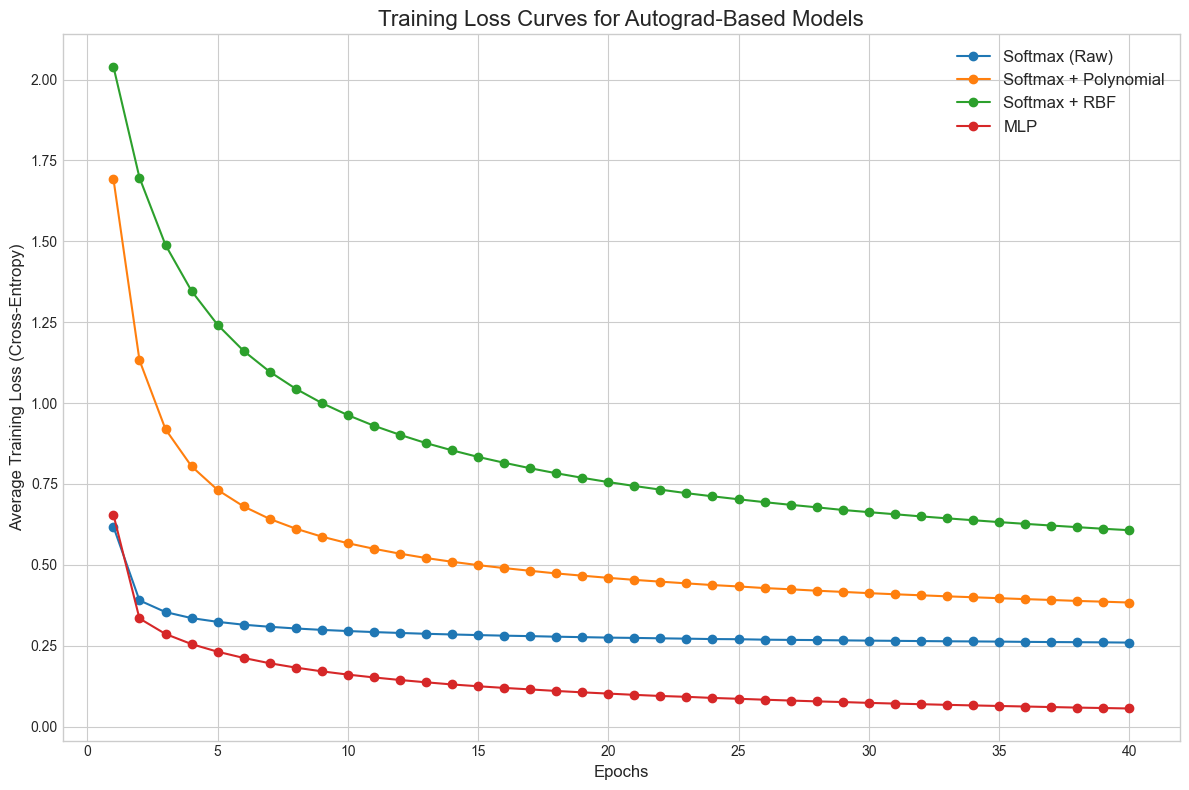

In [9]:
import matplotlib.pyplot as plt
import numpy as np


if 'final_results' not in locals() or not final_results:
    print("Error: `final_results` dictionary not found or is empty.")
    print("Please run the training cells for Models 2, 3, 4, and 5 first.")
else:
    plt.style.use('seaborn-v0_8-whitegrid') 
    fig, ax = plt.subplots(figsize=(12, 8))

    # Models to Plot 
    # As in the project we only need to plot for the following models: Softmax (Raw), Softmax (Poly), Softmax (RBF), and MLP
    autograd_models_to_plot = {
        "Softmax (Raw)": "softmax_raw",
        "Softmax + Polynomial": "softmax_poly",
        "Softmax + RBF": "softmax_rbf",
        "MLP": "mlp"
    }

    # Plotting Loop 
    for display_name, model_key in autograd_models_to_plot.items():
        if model_key in final_results and 'train_losses' in final_results[model_key]:
            
            loss_history = final_results[model_key]['train_losses']
            epochs = range(1, len(loss_history) + 1)
            
            ax.plot(epochs, loss_history, marker='o', linestyle='-', label=display_name)
            
        else:
            print(f"Warning: Could not find training loss data for '{display_name}' (key: '{model_key}'). Skipping.")

    # Final Plot Formatting 
    ax.set_title("Training Loss Curves for Autograd-Based Models", fontsize=16)
    ax.set_xlabel("Epochs", fontsize=12)
    ax.set_ylabel("Average Training Loss (Cross-Entropy)", fontsize=12)
    ax.legend(fontsize=12)
    ax.grid(True)
    plt.tight_layout()
    plt.show()



**5.6 Final Results Summary Table**

To provide a clear, concise summary of our experiments, the following table presents the final held-out **test accuracy** for the best configuration found for each of the five model types. This table allows for a direct comparison of the effectiveness of each approach, from the classical linear model to the Multi-Layer Perceptron.


In [10]:
import pandas as pd
from IPython.display import display

# Check if the results dictionary exists 
if 'final_results' not in locals() or not final_results:
    print("Error: `final_results` dictionary not found or is empty.")
    print("Please run the training cells for all models first.")
else:
    model_order = {
        "ovr_logistic": "Model 1: OvR Logistic Regression",
        "softmax_raw": "Model 2: Softmax (Raw Pixels)",
        "softmax_poly": "Model 3: Softmax + Polynomial",
        "softmax_rbf": "Model 4: Softmax + RBF",
        "mlp": "Model 5: MLP"
    }

    table_data = []
    for model_key, display_name in model_order.items():
        if model_key in final_results:
            result = final_results[model_key]
            test_accuracy_pct = f"{result.get('test_accuracy', 0) * 100:.2f}%"
            
            table_data.append({
                "Model": display_name,
                "Best Test Accuracy": test_accuracy_pct
            })
        else:
            table_data.append({
                "Model": display_name,
                "Best Test Accuracy": "N/A (Not Run)"
            })

    # Create and Display the DataFrame 
    results_df = pd.DataFrame(table_data)
    
    # Styling the DataFrame for better presentation in Jupyter
    styled_df = results_df.style.set_properties(**{'text-align': 'left'})\
                                .set_table_styles([dict(selector='th', props=[('text-align', 'left')])])\
                                .hide() # Hides the index
    
    print("Final Model Performance Summary ---")
    display(styled_df)



Final Model Performance Summary ---


Model,Best Test Accuracy
Model 1: OvR Logistic Regression,91.69%
Model 2: Softmax (Raw Pixels),92.36%
Model 3: Softmax + Polynomial,90.43%
Model 4: Softmax + RBF,84.51%
Model 5: MLP,97.30%
